# Lecture 2 · From fitting a distribution to the VAE

[▶ Open in Colab](https://colab.research.google.com/github/nipunbatra/generative/blob/main/lectures/lecture2/lecture2-generative-models.ipynb) · [Slides](https://nipunbatra.github.io/generative/lectures/lecture2/) · ES 667 Deep Learning, IIT Gandhinagar

This notebook runs the experiments behind the Lecture 2 slides, **in the same order and with the same section numbers** (1.1 … 6.8). Every slide's **▶ Notebook** link jumps to its section here.

Run everything once from the top (*Runtime → Run all*). It needs PyTorch, torchvision, NumPy and matplotlib. In Colab it downloads MNIST (about 12 MB) and the three trained networks from the course repository; from a clone of the repository it uses the local copies. The slides' networks were trained by `lecture2/scripts/train.py` (30 epochs for autoencoders, 50 for VAEs); the extra networks trained here use fewer epochs so the notebook stays quick, and their numbers differ slightly from the slides.

In [1]:
import math, os, urllib.request
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.distributions import Normal
import matplotlib.pyplot as plt

torch.manual_seed(0)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
F64 = torch.float64
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False})
print('device:', DEVICE)

def show_digits(x, ncol=8, size=0.9, title=None):
    # Show a batch of 784-pixel images as ink on paper.
    x = torch.as_tensor(x).detach().float().cpu().reshape(-1, 28, 28).clamp(0, 1)
    n = len(x); nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * size, nrow * size), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis('off')
        if i < n: ax.imshow(1 - x[i], cmap='gray', vmin=0, vmax=1)
    if title: fig.suptitle(title, fontsize=10)
    plt.show()

device: mps


# Part 1 · Why generate?

## 1.1 Things that do not exist

The faces and the real-or-generated digits are on the slides. The fake digits come from the 16-number VAE trained in Part 6.

*Slides: section 1.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

## 1.2 Text, pictures and sound

A language model writes by sampling one word at a time. These are the next-word probabilities on the slide, from SmolLM2-360M; sampling from them gives a different word each time.

*Slides: section 1.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [2]:
words = ['wet', 'sweat', 'damp', 'earth', 'the', 'salt', 'ozone', 'mud', '(any other word)']
probs = torch.tensor([0.1735, 0.0560, 0.0481, 0.0402, 0.0338, 0.0337, 0.0328, 0.0305, 0.5513])
g = torch.Generator().manual_seed(1)
picks = torch.multinomial(probs, 10, replacement=True, generator=g)
print('ten samples of the next word:', [words[i] for i in picks])

ten samples of the next word: ['wet', 'sweat', 'damp', 'sweat', '(any other word)', 'wet', '(any other word)', '(any other word)', '(any other word)', '(any other word)']


## 1.3 Beyond pictures

Weather ensembles, protein design, materials and filling in missing sensor readings: see the slide for references.

*Slides: section 1.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

## 1.4 What they all share

Why not output the average? The average of many 3s is a blur nobody writes. (MNIST is loaded in section 3.1; this cell runs after it if you jump here first.)

*Slides: section 1.4 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

# Part 2 · Fit a distribution, then sample

## 2.1 The data: Old Faithful

272 eruptions of the Old Faithful geyser: how long each eruption lasted, and the wait until the next one (minutes). Azzalini and Bowman (1990), as distributed with R.

*Slides: section 2.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

272 eruptions; first five waits: [79.0, 54.0, 74.0, 62.0, 85.0]
waits between 66 and 76 minutes: 46


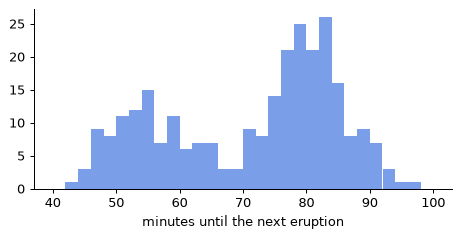

In [3]:
wait = torch.tensor([79, 54, 74, 62, 85, 55, 88, 85, 51, 85, 54, 84, 78, 47, 83, 52, 62, 84, 52, 79, 51, 47, 78, 69, 74, 83, 55, 76, 78, 79, 73, 77, 66, 80, 74, 52, 48, 80, 59, 90, 80, 58, 84, 58, 73, 83, 64, 53, 82, 59, 75, 90, 54, 80, 54, 83, 71, 64, 77, 81, 59, 84, 48, 82, 60, 92, 78, 78, 65, 73, 82, 56, 79, 71, 62, 76, 60, 78, 76, 83, 75, 82, 70, 65, 73, 88, 76, 80, 48, 86, 60, 90, 50, 78, 63, 72, 84, 75, 51, 82, 62, 88, 49, 83, 81, 47, 84, 52, 86, 81, 75, 59, 89, 79, 59, 81, 50, 85, 59, 87, 53, 69, 77, 56, 88, 81, 45, 82, 55, 90, 45, 83, 56, 89, 46, 82, 51, 86, 53, 79, 81, 60, 82, 77, 76, 59, 80, 49, 96, 53, 77, 77, 65, 81, 71, 70, 81, 93, 53, 89, 45, 86, 58, 78, 66, 76, 63, 88, 52, 93, 49, 57, 77, 68, 81, 81, 73, 50, 85, 74, 55, 77, 83, 83, 51, 78, 84, 46, 83, 55, 81, 57, 76, 84, 77, 81, 87, 77, 51, 78, 60, 82, 91, 53, 78, 46, 77, 84, 49, 83, 71, 80, 49, 75, 64, 76, 53, 94, 55, 76, 50, 82, 54, 75, 78, 79, 78, 78, 70, 79, 70, 54, 86, 50, 90, 54, 54, 77, 79, 64, 75, 47, 86, 63, 85, 82, 57, 82, 67, 74, 54, 83, 73, 73, 88, 80, 71, 83, 56, 79, 78, 84, 58, 83, 43, 60, 75, 81, 46, 90, 46, 74], dtype=F64)
duration = torch.tensor([3.6, 1.8, 3.333, 2.283, 4.533, 2.883, 4.7, 3.6, 1.95, 4.35, 1.833, 3.917, 4.2, 1.75, 4.7, 2.167, 1.75, 4.8, 1.6, 4.25, 1.8, 1.75, 3.45, 3.067, 4.533, 3.6, 1.967, 4.083, 3.85, 4.433, 4.3, 4.467, 3.367, 4.033, 3.833, 2.017, 1.867, 4.833, 1.833, 4.783, 4.35, 1.883, 4.567, 1.75, 4.533, 3.317, 3.833, 2.1, 4.633, 2.0, 4.8, 4.716, 1.833, 4.833, 1.733, 4.883, 3.717, 1.667, 4.567, 4.317, 2.233, 4.5, 1.75, 4.8, 1.817, 4.4, 4.167, 4.7, 2.067, 4.7, 4.033, 1.967, 4.5, 4.0, 1.983, 5.067, 2.017, 4.567, 3.883, 3.6, 4.133, 4.333, 4.1, 2.633, 4.067, 4.933, 3.95, 4.517, 2.167, 4.0, 2.2, 4.333, 1.867, 4.817, 1.833, 4.3, 4.667, 3.75, 1.867, 4.9, 2.483, 4.367, 2.1, 4.5, 4.05, 1.867, 4.7, 1.783, 4.85, 3.683, 4.733, 2.3, 4.9, 4.417, 1.7, 4.633, 2.317, 4.6, 1.817, 4.417, 2.617, 4.067, 4.25, 1.967, 4.6, 3.767, 1.917, 4.5, 2.267, 4.65, 1.867, 4.167, 2.8, 4.333, 1.833, 4.383, 1.883, 4.933, 2.033, 3.733, 4.233, 2.233, 4.533, 4.817, 4.333, 1.983, 4.633, 2.017, 5.1, 1.8, 5.033, 4.0, 2.4, 4.6, 3.567, 4.0, 4.5, 4.083, 1.8, 3.967, 2.2, 4.15, 2.0, 3.833, 3.5, 4.583, 2.367, 5.0, 1.933, 4.617, 1.917, 2.083, 4.583, 3.333, 4.167, 4.333, 4.5, 2.417, 4.0, 4.167, 1.883, 4.583, 4.25, 3.767, 2.033, 4.433, 4.083, 1.833, 4.417, 2.183, 4.8, 1.833, 4.8, 4.1, 3.966, 4.233, 3.5, 4.366, 2.25, 4.667, 2.1, 4.35, 4.133, 1.867, 4.6, 1.783, 4.367, 3.85, 1.933, 4.5, 2.383, 4.7, 1.867, 3.833, 3.417, 4.233, 2.4, 4.8, 2.0, 4.15, 1.867, 4.267, 1.75, 4.483, 4.0, 4.117, 4.083, 4.267, 3.917, 4.55, 4.083, 2.417, 4.183, 2.217, 4.45, 1.883, 1.85, 4.283, 3.95, 2.333, 4.15, 2.35, 4.933, 2.9, 4.583, 3.833, 2.083, 4.367, 2.133, 4.35, 2.2, 4.45, 3.567, 4.5, 4.15, 3.817, 3.917, 4.45, 2.0, 4.283, 4.767, 4.533, 1.85, 4.25, 1.983, 2.25, 4.75, 4.117, 2.15, 4.417, 1.817, 4.467], dtype=F64)
print(len(wait), 'eruptions; first five waits:', wait[:5].tolist())
print('waits between 66 and 76 minutes:', int(((wait >= 66) & (wait <= 76)).sum()))
plt.figure(figsize=(6, 2.6)); plt.hist(wait.numpy(), bins=range(40, 101, 2), color='#245EDB', alpha=.6)
plt.xlabel('minutes until the next eruption'); plt.show()

## 2.2 One Gaussian: fit, score, sample

Maximum likelihood for one Gaussian has a formula: the average and the average squared deviation.

*Slides: section 2.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [4]:
mu_hat = wait.mean()
sd_hat = ((wait - mu_hat) ** 2).mean().sqrt()          # divide by n: the maximum-likelihood estimate
bell = Normal(mu_hat, sd_hat)
print(f'mu = {mu_hat:.2f}, sigma = {sd_hat:.2f}')
for x in (54., 71., 80.):
    print(f'density at {x:.0f} minutes: {bell.log_prob(torch.tensor(x, dtype=F64)).exp():.4f}')
print(f'average log-likelihood: {bell.log_prob(wait).mean():.3f}')

mu = 70.90, sigma = 13.57
density at 54 minutes: 0.0135
density at 71 minutes: 0.0294
density at 80 minutes: 0.0235
average log-likelihood: -4.027


draws between 62 and 72 minutes: 66  data: 30


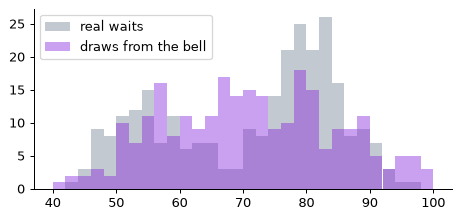

In [5]:
torch.manual_seed(7)
draws = bell.sample((272,))
print('draws between 62 and 72 minutes:', int(((draws >= 62) & (draws <= 72)).sum()), ' data:', int(((wait >= 62) & (wait <= 72)).sum()))
plt.figure(figsize=(6, 2.6)); bins = range(40, 101, 2)
plt.hist(wait.numpy(), bins=bins, color='#9AA5B1', alpha=.6, label='real waits')
plt.hist(draws.numpy(), bins=bins, color='#8B2CDE', alpha=.45, label='draws from the bell'); plt.legend(); plt.show()

## 2.3 Two bumps: a hidden choice

Plot eruption length against the next wait: two kinds of eruption.

*Slides: section 2.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

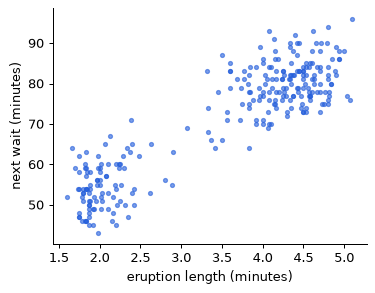

In [6]:
plt.figure(figsize=(4.5, 3.4)); plt.scatter(duration, wait, s=10, color='#245EDB', alpha=.6)
plt.xlabel('eruption length (minutes)'); plt.ylabel('next wait (minutes)'); plt.show()

## 2.4 Fit the mixture, then sample it

The same gradient-descent loop as in Lecture 1. Waits are standardised first, then the fitted values are converted back to minutes.

*Slides: section 2.4 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [7]:
x = (wait - mu_hat) / sd_hat                    # standardised waits
logits = torch.zeros(2, dtype=F64, requires_grad=True)
mu = torch.tensor([-.25, .25], dtype=F64, requires_grad=True)
log_sd = torch.zeros(2, dtype=F64, requires_grad=True)
opt = torch.optim.Adam([logits, mu, log_sd], lr=0.03)
for step in range(600):
    log_pi = torch.log_softmax(logits, 0)
    comp = Normal(mu, log_sd.exp()).log_prob(x[:, None])     # 272 x 2: log N(x_i; mu_k, sd_k^2)
    loss = -torch.logsumexp(log_pi + comp, 1).mean()
    opt.zero_grad(); loss.backward(); opt.step()
pi = torch.softmax(logits, 0).detach()
mu_min = (mu.detach() * sd_hat + mu_hat); sd_min = log_sd.detach().exp() * sd_hat
order = torch.argsort(mu_min); pi, mu_min, sd_min = pi[order], mu_min[order], sd_min[order]
print('shares', pi.numpy().round(3), ' centres', mu_min.numpy().round(2), ' widths', sd_min.numpy().round(2))
avg_ll = torch.logsumexp(pi.log() + Normal(mu_min, sd_min).log_prob(wait[:, None]), 1).mean()
print(f'average log-likelihood: {avg_ll:.3f}  (one Gaussian: {bell.log_prob(wait).mean():.3f})')

shares [0.361 0.639]  centres [54.61 80.09]  widths [5.87 5.87]
average log-likelihood: -3.801  (one Gaussian: -4.027)


mean eruption length, short bump: 2.09 min;  long bump: 4.29 min


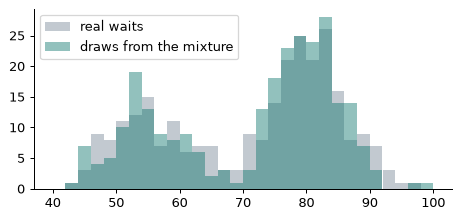

In [8]:
# Which bump does each wait belong to? Compare with the eruption lengths the fit never saw.
logp = pi.log() + Normal(mu_min, sd_min).log_prob(wait[:, None])
long_bump = (logp[:, 1] > logp[:, 0])
print(f'mean eruption length, short bump: {duration[~long_bump].mean():.2f} min;  long bump: {duration[long_bump].mean():.2f} min')
# Sample: pick a bump, then draw a time from it.
torch.manual_seed(41)
k = torch.multinomial(pi, 272, replacement=True)
new = Normal(mu_min[k], sd_min[k]).sample()
plt.figure(figsize=(6, 2.6)); bins = range(40, 101, 2)
plt.hist(wait.numpy(), bins=bins, color='#9AA5B1', alpha=.6, label='real waits')
plt.hist(new.numpy(), bins=bins, color='#0F766E', alpha=.45, label='draws from the mixture'); plt.legend(); plt.show()

## 2.5 How many bumps?

Expectation maximisation (EM) fits a mixture faster than gradient descent; we use it here and in Part 3. Fit on 200 waits, score on the other 72.

*Slides: section 2.5 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [9]:
def em(Z, K, iters=200, seed=0, reg=1e-4):
    # Maximum-likelihood mixture of K full-covariance Gaussians by EM. Z: N x d tensor (float64).
    N, d = Z.shape
    g = torch.Generator().manual_seed(seed)
    C0 = torch.cov(Z.T).reshape(d, d)
    eye = torch.eye(d, dtype=F64) * reg * float(torch.trace(C0)) / d
    means = [Z[torch.randint(N, (1,), generator=g)].squeeze(0)]
    for _ in range(1, K):                                   # spread the starting means out
        dist = torch.stack([((Z - m) ** 2).sum(1) for m in means]).min(0).values
        means.append(Z[torch.multinomial(dist / dist.sum(), 1, generator=g)].squeeze(0))
    means = torch.stack(means); covs = C0.expand(K, d, d).clone() + eye
    logw = torch.full((K,), -math.log(K), dtype=F64)
    for it in range(iters):
        logp = torch.stack([logw[k] + torch.distributions.MultivariateNormal(means[k], covs[k]).log_prob(Z) for k in range(K)])
        tot = torch.logsumexp(logp, 0); R = torch.exp(logp - tot)         # E step: responsibilities
        Nk = R.sum(1) + 1e-10; logw = torch.log(Nk / N); means = (R @ Z) / Nk[:, None]   # M step
        for k in range(K):
            D = Z - means[k]; covs[k] = (R[k][:, None] * D).T @ D / Nk[k] + eye
    return logw.exp(), means, covs, float(tot.mean())

def mog_logpdf(Z, w, means, covs):
    return torch.logsumexp(torch.stack([w[k].log() + torch.distributions.MultivariateNormal(means[k], covs[k]).log_prob(Z) for k in range(len(w))]), 0)

perm = torch.randperm(272, generator=torch.Generator().manual_seed(11))
tr, te = wait[perm[:200]][:, None], wait[perm[200:]][:, None]
for K in range(1, 7):
    best = max((em(tr, K, iters=300, seed=s, reg=1e-3) for s in range(8)), key=lambda r: r[3])
    print(f'K = {K}: train {best[3]:.3f}   held out {mog_logpdf(te, *best[:3]).mean():.3f}')

K = 1: train -4.006   held out -4.086


K = 2: train -3.807   held out -3.793


K = 3: train -3.789   held out -3.821


K = 4: train -3.787   held out -3.825


K = 5: train -3.787   held out -3.825


K = 6: train -3.787   held out -3.825


## 2.6 Two numbers per eruption

With two numbers per example a Gaussian needs a 2 x 2 covariance.

*Slides: section 2.6 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

correlation of length and wait: 0.901
two 2-D bumps: weights [0.356 0.644]  means [[2.04, 54.48], [4.29, 79.97]]  average log-likelihood -4.155


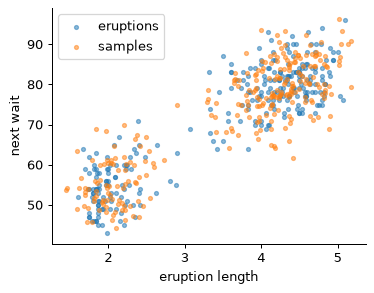

In [10]:
X2 = torch.stack([duration, wait], 1)
w2, m2, c2, ll2 = max((em(X2, 2, iters=300, seed=s, reg=1e-6) for s in range(5)), key=lambda r: r[3])
print('correlation of length and wait:', float(torch.corrcoef(X2.T)[0, 1]).__round__(3))
print('two 2-D bumps: weights', w2.numpy().round(3), ' means', m2.numpy().round(2).tolist(), f' average log-likelihood {ll2:.3f}')
k = torch.multinomial(w2, 272, replacement=True, generator=torch.Generator().manual_seed(4))
S2 = torch.stack([torch.distributions.MultivariateNormal(m2[j], c2[j]).sample() for j in k])
plt.figure(figsize=(4.5, 3.4)); plt.scatter(*X2.T, s=10, alpha=.5, label='eruptions'); plt.scatter(*S2.T, s=10, alpha=.5, label='samples')
plt.xlabel('eruption length'); plt.ylabel('next wait'); plt.legend(); plt.show()

# Part 3 · Images: PCA and Gaussians

## 3.1 An image is 784 numbers

MNIST, grey levels scaled to [0, 1]. Our running example is test digit #90, a 3.

*Slides: section 3.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

torch.Size([60000, 784]) torch.Size([10000, 784]) test digit #90 is a 3
a patch of its pixels (rows 6-15, columns 8-18):
[[0.  0.  0.  0.3 0.8 1.  1.  1.  1.  1.  1. ]
 [0.  0.  0.5 1.  1.  0.9 0.6 0.3 0.2 0.5 1. ]
 [0.  0.4 1.  0.9 0.6 0.1 0.  0.  0.  0.5 1. ]
 [0.  0.1 0.6 0.1 0.  0.  0.  0.  0.2 1.  1. ]
 [0.  0.  0.  0.  0.  0.  0.4 0.6 0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.3 1.  1.  1.  0.9 0.2]
 [0.  0.  0.  0.6 0.9 1.  1.  1.  1.  1.  0.4]
 [0.  0.  0.  0.9 1.  1.  1.  0.7 1.  1.  1. ]
 [0.  0.  0.  0.  0.2 0.  0.  0.  0.2 0.7 1. ]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.  0.1 0.9]]


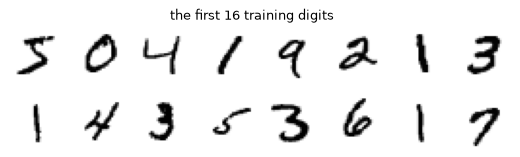

In [11]:
from torchvision.datasets import MNIST
MNIST_ROOT = os.environ.get('MNIST_ROOT', 'data')
have = (Path(MNIST_ROOT) / 'MNIST' / 'raw' / 'train-images-idx3-ubyte').exists()
train_set = MNIST(MNIST_ROOT, train=True, download=not have)
test_set = MNIST(MNIST_ROOT, train=False, download=not have)
Xtr = train_set.data.reshape(-1, 784).double() / 255; ytr = train_set.targets
Xte = test_set.data.reshape(-1, 784).double() / 255; yte = test_set.targets
x3 = Xte[90]
print(Xtr.shape, Xte.shape, 'test digit #90 is a', int(yte[90]))
print('a patch of its pixels (rows 6-15, columns 8-18):'); print(x3.reshape(28, 28)[6:16, 8:19].numpy().round(1))
show_digits(Xtr[:16], title='the first 16 training digits')

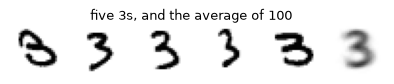

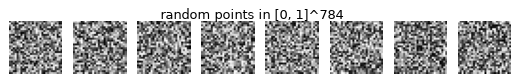

In [12]:
# (section 1.4) the average of 100 test 3s
threes = Xte[yte == 3][:100]
show_digits(torch.cat([threes[:5], threes.mean(0, keepdim=True)]), ncol=6, title='five 3s, and the average of 100')
show_digits(torch.rand(8, 784, generator=torch.Generator().manual_seed(1)), title='random points in [0, 1]^784')

## 3.2 Gaussians on raw pixels

First one Gaussian per pixel, then one 784-dimensional Gaussian with a full covariance.

*Slides: section 3.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

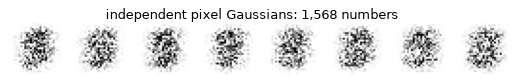

correlation of pixel (14,14) with its right neighbour: 0.78


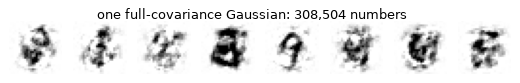

In [13]:
m = Xtr.mean(0); s = Xtr.std(0, correction=0)
g = torch.Generator().manual_seed(1)
show_digits((m + s * torch.randn(8, 784, generator=g, dtype=F64)).clamp(0, 1), title='independent pixel Gaussians: 1,568 numbers')
C = (Xtr - m).T @ (Xtr - m) / len(Xtr)
corr = C / torch.sqrt(torch.outer(C.diagonal(), C.diagonal()) + 1e-12)
c = 14 * 28 + 14
print('correlation of pixel (14,14) with its right neighbour:', round(float(corr[c, c + 1]), 3))
L = torch.linalg.cholesky(C + 1e-4 * torch.eye(784, dtype=F64))
show_digits((m + torch.randn(8, 784, generator=g, dtype=F64) @ L.T).clamp(0, 1), title='one full-covariance Gaussian: 308,504 numbers')

## 3.3 PCA: a few numbers per image

The directions of most spread are the top eigenvectors of the covariance matrix.

*Slides: section 3.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

share of the spread kept by d = 2, 10, 50, 100: [0.168, 0.488, 0.825, 0.915]
d =   1: squared error 47.87
d =   2: squared error 41.34
d =   5: squared error 30.55
d =  10: squared error 26.40
d =  20: squared error 16.40
d =  50: squared error 7.22
d = 100: squared error 2.94


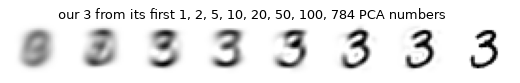

In [14]:
evals, evecs = torch.linalg.eigh(C)
order = torch.argsort(evals, descending=True)
evals, W = evals[order].clamp(min=0), evecs[:, order]
W = W * torch.sign((x3 - m) @ W)                        # cosmetic: the 3's coefficients come out positive
kept = torch.cumsum(evals, 0) / evals.sum()
print('share of the spread kept by d = 2, 10, 50, 100:', [round(float(kept[d - 1]), 3) for d in (2, 10, 50, 100)])
z3 = (x3 - m) @ W                                       # encode: all 784 PCA numbers of our 3
for d in (1, 2, 5, 10, 20, 50, 100):
    xh = m + z3[:d] @ W[:, :d].T                        # decode from the first d
    print(f'd = {d:3d}: squared error {((xh - x3) ** 2).sum():.2f}')
show_digits(torch.stack([(m + z3[:d] @ W[:, :d].T) for d in (1, 2, 5, 10, 20, 50, 100, 784)]), title='our 3 from its first 1, 2, 5, 10, 20, 50, 100, 784 PCA numbers')

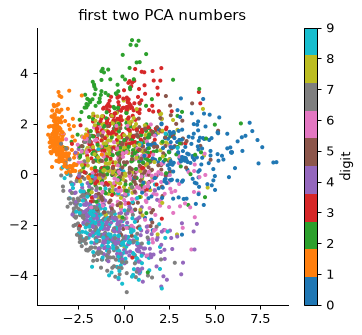

In [15]:
Z2 = (Xte[:2000] - m) @ W[:, :2]
plt.figure(figsize=(4.5, 4)); plt.scatter(*Z2.T, c=yte[:2000], cmap='tab10', s=5); plt.colorbar(label='digit'); plt.title('first two PCA numbers'); plt.show()

## 3.4 Generate from PCA numbers

Fit a distribution to the d PCA numbers of the training digits, sample codes, decode with x = m + W z.

*Slides: section 3.4 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

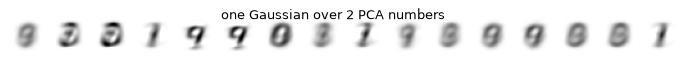

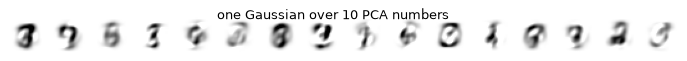

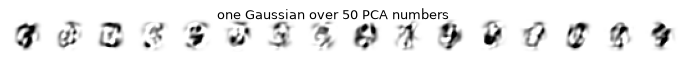

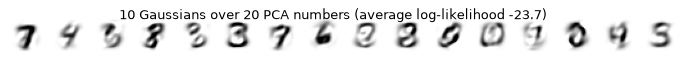

In [16]:
def pca_sample(d, K, n=16, seed=7, sub=30000):
    Z = (Xtr[:sub] - m) @ W[:, :d]
    w, means, covs, ll = em(Z, K, iters=80, seed=d * 100 + K)
    g = torch.Generator().manual_seed(seed)
    k = torch.multinomial(w, n, replacement=True, generator=g)
    z = means[k] + torch.einsum('nij,nj->ni', torch.linalg.cholesky(covs)[k], torch.randn(n, d, generator=g, dtype=F64))
    return (m + z @ W[:, :d].T).clamp(0, 1), ll

for d in (2, 10, 50):
    show_digits(pca_sample(d, 1)[0], ncol=16, size=.6, title=f'one Gaussian over {d} PCA numbers')
xs, ll = pca_sample(20, 10)
show_digits(xs, ncol=16, size=.6, title=f'10 Gaussians over 20 PCA numbers (average log-likelihood {ll:.1f})')

# Part 4 · Autoencoders

## 4.1 From PCA to an autoencoder

One hidden layer of 400 ReLU units on each side, as in Kingma and Welling (2014). The same class becomes a VAE in Part 6.

*Slides: section 4.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [17]:
class AutoEncoder(nn.Module):
    # variational=True: the encoder outputs a mean and a log variance per code number (Part 6).
    def __init__(self, z=2, variational=False):
        super().__init__()
        self.z, self.variational = z, variational
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU(), nn.Linear(400, 2 * z if variational else z))
        self.decoder = nn.Sequential(nn.Linear(z, 400), nn.ReLU(), nn.Linear(400, 784), nn.Sigmoid())
    def encode(self, x):
        h = self.encoder(x)
        return h.chunk(2, dim=1) if self.variational else (h, None)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu) if self.variational else mu
        return self.decoder(z), mu, logvar

SIGMA = 0.2                                              # the VAE's pixel noise (Part 6)
def loss_fn(model, x, target, beta=1.0):
    x_hat, mu, logvar = model(x)
    sse = ((x_hat - target) ** 2).sum(1)                 # squared error summed over the 784 pixels
    if not model.variational:
        return sse.mean()
    kl = 0.5 * (mu ** 2 + logvar.exp() - logvar - 1).sum(1)
    return (sse / (2 * SIGMA ** 2) + beta * kl).mean()

def train(model, epochs, beta=1.0, mask=0.0, seed=0, lr=1e-3):
    torch.manual_seed(seed); model.to(DEVICE).train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    X = Xtr.float().to(DEVICE)
    for epoch in range(epochs):
        for idx in torch.randperm(len(X)).split(128):
            xb = X[idx]; inp = xb * (torch.rand_like(xb) > mask) if mask else xb
            loss = loss_fn(model, inp, xb, beta)
            opt.zero_grad(); loss.backward(); opt.step()
    return model.eval().cpu()

@torch.no_grad()
def test_sse(model, X=None):
    X = (Xte if X is None else X).float()
    mu, _ = model.encode(X)
    return float(((model.decoder(mu) - X) ** 2).sum(1).mean())

def load_trained(name, z, variational):
    # The slides' networks: from lecture2/models in a clone, else downloaded from the repository.
    path = Path('models') / f'{name}.pt'
    if not path.exists():
        path.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/nipunbatra/generative/main/lectures/lecture2/models/{name}.pt', path)
    net = AutoEncoder(z, variational)
    sd = torch.load(path, map_location='cpu', weights_only=False)['state_dict']
    if variational:
        sd = {k: v for k, v in sd.items()}
    net.load_state_dict(sd); return net.eval()

## 4.2 Train one

Always look at the untrained network first. Then load the trained 2-number autoencoder (or set `RETRAIN = True` to train it here: 30 epochs, under a minute on a GPU).

*Slides: section 4.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

untrained outputs lie between 0.38 and 0.64; test squared error 182.5 per image
trained: test squared error 31.08, training 29.81 (first 10,000 training digits)


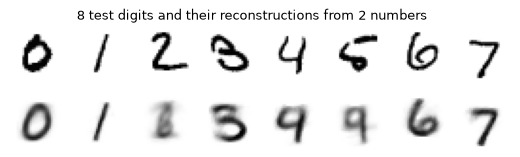

In [18]:
torch.manual_seed(0)
fresh = AutoEncoder(z=2).eval()
with torch.no_grad(): out = fresh(Xte[:8].float())[0]
print(f'untrained outputs lie between {out.min():.2f} and {out.max():.2f}; test squared error {test_sse(fresh):.1f} per image')
RETRAIN = False
ae2 = train(AutoEncoder(z=2), epochs=30) if RETRAIN else load_trained('ae2', 2, False)
print(f'trained: test squared error {test_sse(ae2):.2f}, training {test_sse(ae2, Xtr[:10000]):.2f} (first 10,000 training digits)')
with torch.no_grad(): rec = ae2.decoder(ae2.encode(Xte[[3, 2, 1, 18, 4, 8, 11, 0]].float())[0])
show_digits(torch.cat([Xte[[3, 2, 1, 18, 4, 8, 11, 0]], rec.double()]), title='8 test digits and their reconstructions from 2 numbers')

## 4.3 How many numbers in the code?

Train autoencoders with wider codes (10 epochs each here; 30 on the slides) and compare with PCA at the same size.

*Slides: section 4.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [19]:
aes = {2: ae2}
for z in (8, 16, 128):
    aes[z] = train(AutoEncoder(z=z), epochs=10, seed=z)
for z, net in aes.items():
    Zt = (Xte - m) @ W[:, :z]
    pca = float((((m + Zt @ W[:, :z].T) - Xte) ** 2).sum(1).mean())
    print(f'code of {z:3d} numbers: autoencoder {test_sse(net):6.2f}   PCA {pca:6.2f}')

code of   2 numbers: autoencoder  31.08   PCA  43.64
code of   8 numbers: autoencoder  14.35   PCA  29.35
code of  16 numbers: autoencoder   8.08   PCA  21.06
code of 128 numbers: autoencoder   2.20   PCA   3.30


## 4.4 What codes are good for

Search by code, and a denoising autoencoder.

*Slides: section 4.4 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

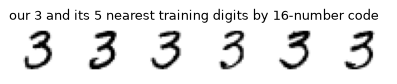

squared error against the clean digits: plain 35.8, denoising 13.4


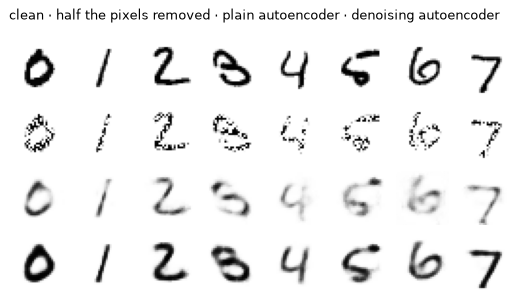

In [20]:
with torch.no_grad():
    codes = aes[16].encode(Xtr.float())[0]; q = aes[16].encode(x3[None].float())[0]
nearest = torch.cdist(q, codes)[0].argsort()[:5]
show_digits(torch.cat([x3[None], Xtr[nearest]]), ncol=6, title='our 3 and its 5 nearest training digits by 16-number code')
dae = train(AutoEncoder(z=16), epochs=10, mask=0.5, seed=12)
g = torch.Generator().manual_seed(12); xw = Xte[[3, 2, 1, 18, 4, 8, 11, 0]]
damaged = xw * (torch.rand(xw.shape, generator=g, dtype=F64) > 0.5)
with torch.no_grad():
    plain, clean = [n.decoder(n.encode(damaged.float())[0]).double() for n in (aes[16], dae)]
print(f'squared error against the clean digits: plain {((plain - xw) ** 2).sum(1).mean():.1f}, denoising {((clean - xw) ** 2).sum(1).mean():.1f}')
show_digits(torch.cat([xw, damaged, plain, clean]), title='clean · half the pixels removed · plain autoencoder · denoising autoencoder')

# Part 5 · Can an autoencoder generate?

## 5.1 Decode a random code

Feed draws from N(0, I) to the decoders.

*Slides: section 5.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

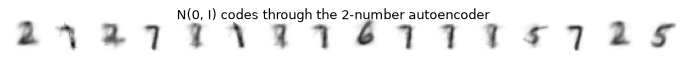

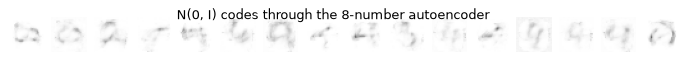

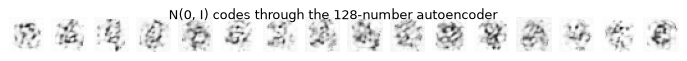

In [21]:
for z in (2, 8, 128):
    with torch.no_grad(): xs = aes[z].decoder(torch.randn(16, z, generator=torch.Generator().manual_seed(5)))
    show_digits(xs, ncol=16, size=.6, title=f'N(0, I) codes through the {z}-number autoencoder')

## 5.2 Where the codes are

Overlay N(0, I) draws on the codes of real test digits; decode a grid; measure how far apart codes of the same digit are.

*Slides: section 5.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

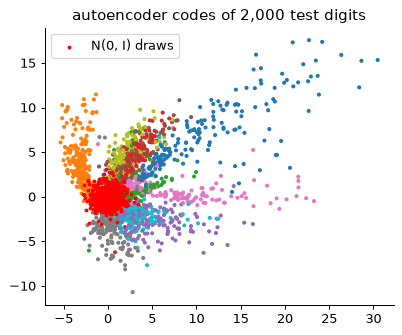

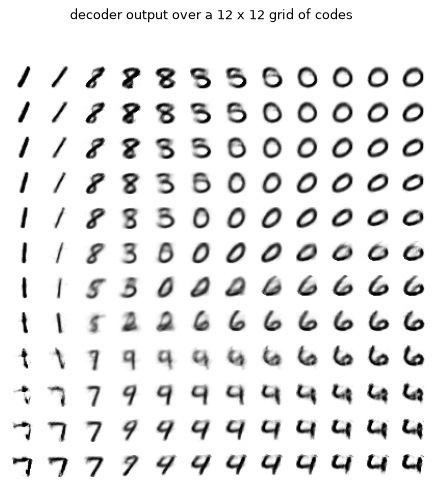

  2 numbers: two 0s   8.68 apart, a 0 and a 1  15.11 apart, ratio 0.57
  8 numbers: two 0s  10.18 apart, a 0 and a 1  23.11 apart, ratio 0.44
 16 numbers: two 0s  14.70 apart, a 0 and a 1  24.47 apart, ratio 0.60
128 numbers: two 0s  23.46 apart, a 0 and a 1  26.54 apart, ratio 0.88


In [22]:
with torch.no_grad(): C2 = ae2.encode(Xte[:2000].float())[0]
prior = torch.randn(500, 2, generator=torch.Generator().manual_seed(6))
plt.figure(figsize=(5, 4)); plt.scatter(*C2.T, c=yte[:2000], cmap='tab10', s=5); plt.scatter(*prior.T, s=4, c='red', label='N(0, I) draws')
plt.legend(); plt.title('autoencoder codes of 2,000 test digits'); plt.show()
lo, hi = C2.quantile(.01, 0), C2.quantile(.99, 0)
gx, gy = torch.linspace(lo[0], hi[0], 12), torch.linspace(hi[1], lo[1], 12)
grid = torch.stack(torch.meshgrid(gy, gx, indexing='ij')[::-1], -1).reshape(-1, 2)
with torch.no_grad(): show_digits(ae2.decoder(grid), ncol=12, size=.5, title='decoder output over a 12 x 12 grid of codes')
def spread(net):
    with torch.no_grad(): z0, z1 = net.encode(Xte[yte == 0][:100].float())[0], net.encode(Xte[yte == 1][:100].float())[0]
    same = torch.pdist(z0).mean(); cross = torch.cdist(z0, z1).mean()
    return float(same), float(cross)
for z, net in aes.items():
    a, b = spread(net); print(f'{z:3d} numbers: two 0s {a:6.2f} apart, a 0 and a 1 {b:6.2f} apart, ratio {a / b:.2f}')

## 5.3 Fit a density to the codes

Part 3's recipe: fit a mixture to the codes of the training digits, then sample codes from it.

*Slides: section 5.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

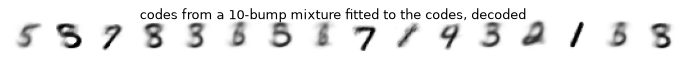

In [23]:
with torch.no_grad(): Ctr = ae2.encode(Xtr.float())[0].double()
w, means, covs, ll = em(Ctr, 10, iters=200, seed=31)
k = torch.multinomial(w, 16, replacement=True, generator=torch.Generator().manual_seed(8))
zs = torch.stack([torch.distributions.MultivariateNormal(means[j], covs[j]).sample() for j in k])
with torch.no_grad(): show_digits(ae2.decoder(zs.float()), ncol=16, size=.6, title='codes from a 10-bump mixture fitted to the codes, decoded')

# Part 6 · The variational autoencoder

## 6.1 The generative story

z ~ N(0, I), then x | z ~ N(decoder(z), 0.2² I). Load the trained 2-number and 16-number VAEs (50 epochs).

*Slides: section 6.1 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [24]:
vae2 = load_trained('vae2', 2, True); vae16 = load_trained('vae16', 16, True)
const = 784 * math.log(SIGMA * math.sqrt(2 * math.pi))
@torch.no_grad()
def log_lik(net, x, Z):                     # log p(x | z) for a batch of codes Z
    return -((net.decoder(Z.float()).double() - x) ** 2).sum(1) / (2 * SIGMA ** 2) - const
print(f'the constant 784 log(sigma sqrt(2 pi)) = {const:.2f}')

the constant 784 log(sigma sqrt(2 pi)) = -541.35


## 6.2 Which code made this 3?

With two numbers per code we can compute the posterior and the evidence on a grid. With 16 we could not.

*Slides: section 6.2 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

log p(x) by adding rectangles: 244.07


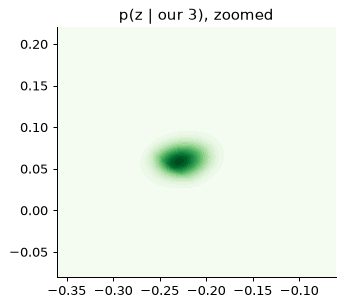

S =     10: estimate     5.89
S =    100: estimate   224.77
S =   1000: estimate   236.37
S =  10000: estimate   244.93


S = 100000: estimate   244.05


In [25]:
with torch.no_grad(): mu3, lv3 = vae2.encode(x3[None].float())
mu3, sd3 = mu3[0].double(), (0.5 * lv3[0].double()).exp()
half, n = 0.15, 241                                  # a fine window around the posterior
ax_x = torch.linspace(mu3[0] - half, mu3[0] + half, n, dtype=F64); ax_y = torch.linspace(mu3[1] - half, mu3[1] + half, n, dtype=F64)
Zg = torch.stack(torch.meshgrid(ax_x, ax_y, indexing='xy'), -1).reshape(-1, 2)
lj = log_lik(vae2, x3, Zg) - 0.5 * (Zg ** 2).sum(1) - math.log(2 * math.pi)    # log p(x | z) + log p(z)
cell = float((ax_x[1] - ax_x[0]) * (ax_y[1] - ax_y[0]))
log_px = float(torch.logsumexp(lj, 0)) + math.log(cell)
print(f'log p(x) by adding rectangles: {log_px:.2f}')
plt.figure(figsize=(4, 3.6)); plt.contourf(ax_x, ax_y, torch.softmax(lj, 0).reshape(n, n), levels=20, cmap='Greens'); plt.title('p(z | our 3), zoomed'); plt.show()
# Naive Monte Carlo: average p(x | z) over prior draws.
g = torch.Generator().manual_seed(22)
for S in (10, 100, 1000, 10000, 100000):
    z = torch.randn(S, 2, generator=g, dtype=F64)
    print(f'S = {S:6d}: estimate {float(torch.logsumexp(log_lik(vae2, x3, z), 0)) - math.log(S):8.2f}')

## 6.3 Variational inference for one image

Lecture 1's tool: fit q(z) = N(m, diag s²) to this one posterior by maximising the ELBO with reparameterised draws.

*Slides: section 6.3 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [26]:
def elbo(net, x, m_, s_, draws=20000, seed=21):
    eps = torch.randn(draws, 2, generator=torch.Generator().manual_seed(seed), dtype=F64)
    kl = 0.5 * float((m_ ** 2 + s_ ** 2 - 2 * s_.log() - 1).sum())
    return float(log_lik(net, x, m_ + s_ * eps).mean()) - kl

torch.manual_seed(23)
mq = torch.zeros(2, requires_grad=True); ls = torch.zeros(2, requires_grad=True)
opt = torch.optim.Adam([mq, ls], lr=0.05)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: 1.0 if t < 800 else 0.2)
x3f = x3.float()
for step in range(1200):
    zq = mq + ls.exp() * torch.randn(64, 2)                                 # reparameterised draws
    recon = -((vae2.decoder(zq) - x3f) ** 2).sum(1) / (2 * SIGMA ** 2) - const
    kl = 0.5 * (mq ** 2 + (2 * ls).exp() - 2 * ls - 1).sum()
    loss = -(recon.mean() - kl)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
m_vi, s_vi = mq.detach().double(), ls.detach().double().exp()
print('per-image q: mean', m_vi.numpy().round(4), ' sd', s_vi.numpy().round(4), f' ELBO {elbo(vae2, x3, m_vi, s_vi):.2f}')

per-image q: mean [-0.2275  0.062 ]  sd [0.0182 0.015 ]  ELBO 244.05


## 6.4 An encoder does it for every image

The encoder outputs q for any image in one forward pass. Compare its ELBO with the per-image fit and with log p(x).

*Slides: section 6.4 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [27]:
print('encoder q: mean', mu3.numpy().round(4), ' sd', sd3.numpy().round(4))
print(f'log p(x) {log_px:.2f}  |  per-image q {elbo(vae2, x3, m_vi, s_vi):.2f}  |  encoder q {elbo(vae2, x3, mu3, sd3):.2f}')

encoder q: mean [-0.2106  0.0702]  sd [0.013  0.0104]
log p(x) 244.07  |  per-image q 244.05  |  encoder q 243.37


## 6.5 The loss, term by term

One reparameterised draw for our 3, with numbers.

*Slides: section 6.5 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [28]:
eps = torch.tensor([0.5, -1.0], dtype=F64)
z = mu3 + sd3 * eps
with torch.no_grad(): xh = vae2.decoder(z[None].float())[0].double()
sse = float(((xh - x3) ** 2).sum()); kl = 0.5 * float((mu3 ** 2 + sd3 ** 2 - 2 * sd3.log() - 1).sum())
print(f'z = {z.numpy().round(4)}; squared error {sse:.2f}; reconstruction term {sse / (2 * SIGMA ** 2):.1f}; KL {kl:.2f}; loss {sse / (2 * SIGMA ** 2) + kl:.1f}')

z = [-0.2042  0.0599]; squared error 23.18; reconstruction term 289.8; KL 7.94; loss 297.7


## 6.6 What the VAE learned

Sample z ~ N(0, I) and decode; look at where the codes are.

*Slides: section 6.6 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

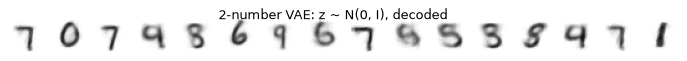

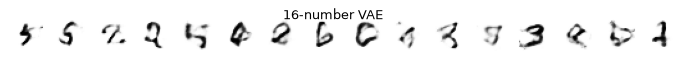

codes of all test digits: mean [-0.2  -0.25]  sd [1.75 1.72]


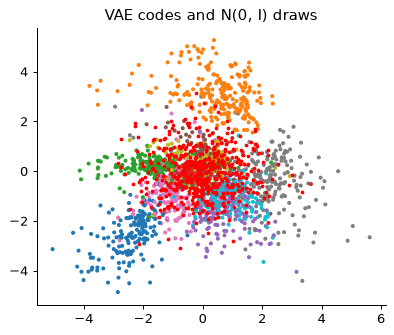

In [29]:
g = torch.Generator().manual_seed(5)
with torch.no_grad():
    show_digits(vae2.decoder(torch.randn(16, 2, generator=g)), ncol=16, size=.6, title='2-number VAE: z ~ N(0, I), decoded')
    show_digits(vae16.decoder(torch.randn(16, 16, generator=torch.Generator().manual_seed(5))), ncol=16, size=.6, title='16-number VAE')
    V2 = vae2.encode(Xte.float())[0]
print('codes of all test digits: mean', V2.mean(0).numpy().round(2), ' sd', V2.std(0).numpy().round(2))
plt.figure(figsize=(5, 4)); plt.scatter(*V2[:2000].T, c=yte[:2000], cmap='tab10', s=5); plt.scatter(*prior.T, s=4, c='red'); plt.title('VAE codes and N(0, I) draws'); plt.show()

## 6.7 The KL weight β

Train 2-number VAEs with β = 0 and β = 256 (10 epochs each) and compare with β = 1.

*Slides: section 6.7 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*

In [30]:
for beta, net in ((0.0, train(AutoEncoder(2, True), epochs=10, beta=0.0, seed=40)), (1.0, vae2), (256.0, train(AutoEncoder(2, True), epochs=10, beta=256.0, seed=41))):
    with torch.no_grad():
        mu_, lv_ = net.encode(Xte.float())
        kl = 0.5 * (mu_ ** 2 + lv_.exp() - lv_ - 1).sum(1).mean()
    print(f'beta = {beta:5.0f}: KL per image {kl:6.2f}, average sigma of q {torch.exp(0.5 * lv_).mean():.4f}, spread of codes {mu_.std(0).mean():.2f}')

beta =     0: KL per image  37.69, average sigma of q 0.0031, spread of codes 4.45
beta =     1: KL per image   9.02, average sigma of q 0.0354, spread of codes 1.74
beta =   256: KL per image   0.00, average sigma of q 0.9997, spread of codes 0.01


## 6.8 Wrap-up

From one number per example to 784: a hidden code first, then the data. Next lectures: GANs, then diffusion.

*Slides: section 6.8 of the [slides](https://nipunbatra.github.io/generative/lectures/lecture2/).*